<a href="https://colab.research.google.com/github/panagiotachristou/nlp-sentiment-classification/blob/main/2nd_nlp_text_classification.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Based on the course lab notebook (Text Classification, 2026). My additions: SVD tuning, tuning on a fixed development set, result tables, learning curves, dataset statistics.

In [ ]:
# Install dependencies
%pip install "scikit-learn==1.9.1" "numpy==2.3.5" "scipy==1.17.0" "pandas==2.2.3" "matplotlib==3.10.8" "nltk==3.10.4" "umap-learn==0.5.12" "spacy==3.8.18" "spacy-lookups-data==1.0.5"

In [ ]:
from pathlib import Path
from time import perf_counter
import re
import unicodedata

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.model_selection import train_test_split

SEED = 2026
N_JOBS = 1
DATA_DIR = Path('data')
DATA_DIR.mkdir(exist_ok=True)
CLASS_NAMES = ['Negative', 'Positive']  # 0, 1
NEG, POS, INK = '#d26936', '#286fb5', '#233247'
CLASS_COLORS = [NEG, POS]
plt.rcParams.update({
    'figure.figsize': (9, 4.3), 'figure.dpi': 115,
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.titleweight': 'bold', 'axes.titlesize': 12,
    'font.size': 10.5, 'axes.axisbelow': True,
    'grid.color': '#e4e7ec', 'grid.alpha': 0.8,
})

Data collection

The corpus consists of 2,000 movie reviews (Cornell polarity dataset v2.0), 1,000 positive and 1,000 negative.

In [ ]:
import hashlib
import urllib.request

DATA_URL = 'https://www.cs.cornell.edu/people/pabo/movie-review-data/review_polarity.tar.gz'
ARCHIVE = DATA_DIR / 'review_polarity.tar.gz'
EXPECTED_SHA256 = 'fc0dccc2671af5db3c5d8f81f77a1ebfec953ecdd422334062df61ede36b2179'
if not ARCHIVE.exists():
    try:
        with urllib.request.urlopen(DATA_URL, timeout=60) as response:
            payload = response.read()
    except OSError as exc:
        raise RuntimeError('Put the supplied review_polarity.tar.gz in data/ and rerun.') from exc
    if hashlib.sha256(payload).hexdigest() != EXPECTED_SHA256:
        raise ValueError('Unexpected download checksum.')
    ARCHIVE.write_bytes(payload)
payload = ARCHIVE.read_bytes()
assert hashlib.sha256(payload).hexdigest() == EXPECTED_SHA256
print('Verified original Cornell archive:', len(payload), 'bytes')

Verified original Cornell archive: 3127238 bytes


Load

Archived file .tar is opened staright into memory without unpacking it. It contains the folder txt_sentoken with 2 subfolders: neg/*.txt and pos/*.txt.

A loop runs through every text in pos and neg. For each review, save a row with its text, its label (1 if it’s in pos, 0 if in neg) and its file name.

All rows are put into a table (reviews).

Assertions:

1.   exactly 2,000 reviews, 1,000 negative and 1,000 positive
2.   none review empty
3.   none review duplicated

Finally, it prints how many reviews were loaded and what 0 and 1 mean.


In [ ]:
import tarfile
import io

rows = []
with tarfile.open(fileobj=io.BytesIO(payload), mode='r:gz') as archive:
    for member in sorted(archive.getmembers(), key=lambda item: item.name):
        parts = Path(member.name).parts
        if (member.isfile() and len(parts) == 3 and parts[0] == 'txt_sentoken'
                and parts[1] in {'neg', 'pos'} and parts[2].endswith('.txt')):
            rows.append({'text': archive.extractfile(member).read().decode('utf-8'),
                         'label': int(parts[1] == 'pos'), 'file': member.name})

# converts list to table. Each dic one row in table, each field name becomes one column
# reviews columns: text, label, file
reviews = pd.DataFrame(rows)
assert reviews.shape[0] == 2000
assert reviews.label.value_counts().sort_index().tolist() == [1000, 1000]
assert reviews.text.str.strip().ne('').all()

dedup_text = reviews.text.str.replace(r'\s+', ' ', regex=True).str.strip()

assert not dedup_text.duplicated().any(), 'Resolve duplicated texts before splitting.'

print('Class mapping:', dict(enumerate(CLASS_NAMES)))

Class mapping: {0: 'Negative', 1: 'Positive'}


**Split text**

 Split the 2,000 reviews into train (1,050), dev (350) and test (600), keeping 50/50 neg/pos in each set.
 The test set is set aside first and stays untouched until the final evaluation; the picture shows the three sets.

Training class counts: [525 525] | Validation class counts: [175 175]


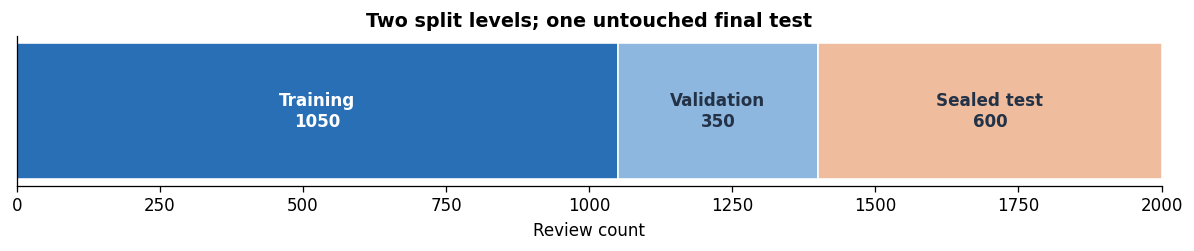

In [ ]:
# stratify=reviews.label: keep the same class proportions in both parts
# random_state=SEED: the random cut is the same every run, so the results are reproducible.
trainval, sealed_test = train_test_split(
    reviews, test_size=0.30, stratify=reviews.label, random_state=SEED)

trainval = trainval.reset_index(drop=True)

# columns to arrays
X_trainval = trainval.text.to_numpy()  # texts
y_trainval = trainval.label.to_numpy() # labels

# Split into train and dev
X_train, X_val, y_train, y_val = train_test_split(
    X_trainval, y_trainval, test_size=0.25, random_state=SEED,
    # G01 — Preserve class proportions when splitting the training + validation pool.
    stratify=y_trainval,
)
assert len(X_train) == 1050 and len(X_val) == 350 and len(sealed_test) == 600
assert not set(trainval.file) & set(sealed_test.file)
print('Training class counts:', np.bincount(y_train), '| Validation class counts:', np.bincount(y_val))


fig, ax = plt.subplots(figsize=(10.5, 2.3))
parts = [('Training', len(X_train), POS), ('Validation', len(X_val), '#8eb7df'),
         ('Sealed test', len(sealed_test), '#efbd9d')]
left = 0
for name, count, color in parts:
    ax.barh(0, count, left=left, height=0.55, color=color, edgecolor='white')
    ax.text(left + count / 2, 0, f'{name}\n{count}', ha='center', va='center',
            color='white' if name == 'Training' else INK, fontweight='bold')
    left += count
ax.set(xlim=(0, 2000), xlabel='Review count', title='Two split levels; one untouched final test')
ax.set_yticks([])
plt.tight_layout(); plt.show()

**Data exploration (training + validation(dev) sets only)**

 We count the negative and positive reviews and plot the distribution of review lengths (in tokens) per class, using only the 1,400 training and development reviews so the test set stays unseen. This shows whether the classes are balanced and whether review length differs between the two classes.

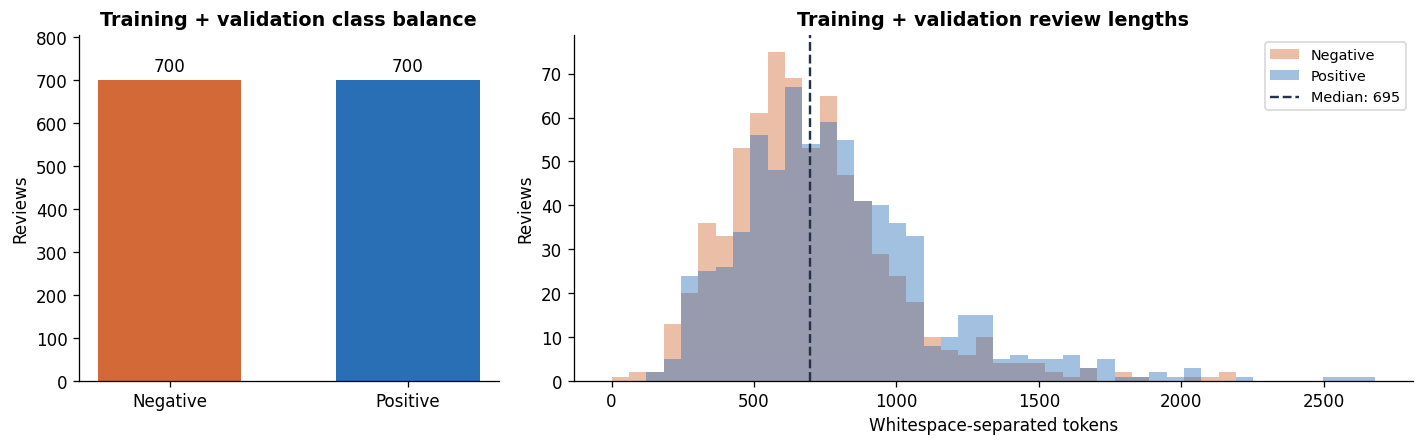

In [ ]:
review_lengths = trainval.text.str.split().str.len().to_numpy()
counts = np.bincount(y_trainval)
fig, axes = plt.subplots(1, 2, figsize=(12.5, 4), gridspec_kw={'width_ratios': [1, 2]})
bars = axes[0].bar(CLASS_NAMES, counts, color=CLASS_COLORS, width=0.6)
axes[0].bar_label(bars, padding=3)
axes[0].set(title='Training + validation class balance', ylabel='Reviews', ylim=(0, counts.max() * 1.15))
bins = np.linspace(0, review_lengths.max() + 1, 45)
for label, color in enumerate(CLASS_COLORS):
    axes[1].hist(review_lengths[y_trainval == label], bins=bins, alpha=0.43,
                 color=color, label=CLASS_NAMES[label])
axes[1].axvline(np.median(review_lengths), color=INK, ls='--',
                label=f'Median: {np.median(review_lengths):.0f}')
axes[1].set(title='Training + validation review lengths', xlabel='Whitespace-separated tokens', ylabel='Reviews')
axes[1].legend(fontsize=9)
plt.tight_layout(); plt.show()

**Preprocess dataset / Data cleaning**

I clean each review with a small function from the lab (normalize_text). It turns everything to lowercase, replaces special characters like curly apostrophes, writes negations in full (“isn’t” or “is n’t” → “is not”) and removes extra spaces. This way the same word always looks the same, and especially “not” is always one word, which is important for sentiment.

I did not remove stop words, because the usual stop-word lists include “not” and “no”. I also did not remove punctuation before fixing the negations, because then “can’t” would become “can”.


In [ ]:
def normalize_text(text):
    text = unicodedata.normalize('NFKC', str(text)).replace('’', "'").lower()
    # Expand the irregular stems before the generic n't rule.
    text = re.sub(r"\bcan't\b", 'can not', text)
    text = re.sub(r"\bwon't\b", 'will not', text)
    text = re.sub(r"\bshan't\b", 'shall not', text)
    text = re.sub(r"\bcannot\b", 'can not', text)
    # Also handle already tokenized contractions found in processed corpora.
    text = re.sub(r"\bca\s+n't\b", 'can not', text)
    text = re.sub(r"\bwo\s+n't\b", 'will not', text)
    text = re.sub(r"n['’]t\b", ' not', text)
    return re.sub(r'\s+', ' ', text).strip()

preprocess_examples = ["I can't recommend this film.", "This isn't good.",
                       "I did not like it.", "It wasn't boring."]
display(pd.DataFrame({'original': preprocess_examples,
                      'normalized': [normalize_text(t) for t in preprocess_examples]}))
assert normalize_text("I can't recommend this film.") == 'i can not recommend this film.'
assert normalize_text("This isn't good.") == 'this is not good.'
assert normalize_text('I can’t recommend this film.') == 'i can not recommend this film.'
assert normalize_text("it did n't work") == 'it did not work'

,original,normalized
0,I can't recommend this film.,i can not recommend this film.
1,This isn't good.,this is not good.
2,I did not like it.,i did not like it.
3,It wasn't boring.,it was not boring.


**Feature extraction (TF-IDF n-gram features)**


## Feature extraction (TF-IDF n-gram features)

Let $c(t,d)$ be a term's count in document $d$, $df(t)$ its training document frequency, and $n$ the number of training documents. Our main model uses

$$
tf(t,d) =
\begin{cases}
1+\ln c(t,d), & c(t,d)>0,\\
0, & c(t,d)=0,
\end{cases}
\qquad
idf(t)=\ln\left(\frac{1+n}{1+df(t)}\right)+1.
$$

The unnormalized weight is $w_{t,d}=tf(t,d)\,idf(t)$; L2 normalization gives

$$
x_d=\frac{w_d}{\lVert w_d\rVert_2}
$$

for a nonzero row. Thus a document becomes a sparse vector, with one column per token or n-gram.

`max_features=5000` caps the vocabulary by corpus term frequency, not by predictive importance. `min_df=2` removes terms seen in fewer than two training documents. No stopword list is applied. The default word tokenizer drops punctuation and one-character tokens; bigrams preserve some local word order.


In [ ]:
from sklearn.feature_extraction.text import TfidfVectorizer

def make_tfidf(ngram_range=(1, 2), max_features=5000):
    # G02 — Represent each review with both word unigrams and word bigrams.
    # min_df a word must appear at least twice to be included
    # 1 + ln(count) => sublinear_tf=True. This means if a word appears many times in a review, don’t let it be too loud. Ten times isn’t worth ten times more than once
    # stop words are not thrown away
     return TfidfVectorizer(preprocessor=normalize_text, ngram_range=ngram_range,
                           min_df=2, max_features=max_features, sublinear_tf=True,
                           stop_words=None, norm='l2')

vectorizer = make_tfidf()
# G03 — Learn vocabulary and IDF on training text, then build its feature matrix.
# 1,050 rows × |V| columns (words).
X_train_tfidf = vectorizer.fit_transform(X_train)

# G04 — Use the learned vocabulary and IDF on validation text without a new fit.
# fit = learn. For dev data we don't want them learned and added in vocabulary
# result: a table of 350 rows × |V| columns.
X_val_tfidf = vectorizer.transform(X_val)

# vacabulary
feature_names = vectorizer.get_feature_names_out()

# same num of boxes
assert X_train_tfidf.shape[1] == X_val_tfidf.shape[1]
# not all zeros
assert np.all(np.asarray(X_train_tfidf.getnnz(axis=1)) > 0)

print('Training matrix:', X_train_tfidf.shape, '| Validation matrix:', X_val_tfidf.shape)
print('Example features:', feature_names[::500])

# small test with2 sentences
negation_vectorizer = TfidfVectorizer(preprocessor=normalize_text, ngram_range=(1, 2))
negation_vectorizer.fit(["This isn't good.", 'This is good.'])
assert 'not good' in negation_vectorizer.vocabulary_

Training matrix: (1050, 5000) | Validation matrix: (350, 5000)
Example features: ['000' 'before it' 'decided to' 'for few' 'in her' 'lucas' 'one liners'
 'scorsese' 'that there' 'touching']


Vocabulary

In [ ]:
unigrams = TfidfVectorizer(preprocessor=normalize_text, ngram_range=(1, 1)).fit(X_train)
bigrams = TfidfVectorizer(preprocessor=normalize_text, ngram_range=(1, 2)).fit(X_train)
bigrams_min2 = TfidfVectorizer(preprocessor=normalize_text, ngram_range=(1, 2), min_df=2).fit(X_train)

print('Unigrams:', len(unigrams.vocabulary_))
print('Unigrams + bigrams:', len(bigrams.vocabulary_))
print('Unigrams + bigrams in at least 2 reviews:', len(bigrams_min2.vocabulary_))
print('Used by the model:', len(feature_names))

Unigrams: 30678
Unigrams + bigrams: 331563
Unigrams + bigrams in at least 2 reviews: 79741
Used by the model: 5000


**Compress the numbers (SVD)**

Used lab's code removing details about knn

Created a function so I can later on fine tune SVD for diff sizes

In [ ]:
from sklearn.decomposition import TruncatedSVD

def apply_svd(n_components, X_tr, X_va):
    svd = TruncatedSVD(n_components=n_components, random_state=SEED)
    X_tr_svd = svd.fit_transform(X_tr)
    X_va_svd = svd.transform(X_va)
    return svd, X_tr_svd, X_va_svd

svd, X_train_svd, X_val_svd = apply_svd(300, X_train_tfidf, X_val_tfidf)
print('Latent representation:', X_train_svd.shape, X_val_svd.shape)



Latent representation: (1050, 300) (350, 300)


**Baseline**

`DummyClassifier(strategy='most_frequent')` predicts the most frequent training
class without using the review's words. `prior` produces the same labels while
returning empirical class priors; `stratified` and `uniform` generate randomized
predictions; `constant` always chooses a specified label.

In [ ]:
from sklearn.metrics import (accuracy_score, f1_score, classification_report,
                             ConfusionMatrixDisplay)
results = {}
fitted_models = {}

def evaluate(model, name, X_tr=None, X_va=None):
    X_tr = X_train_tfidf if X_tr is None else X_tr
    X_va = X_val_tfidf if X_va is None else X_va
    start = perf_counter()
    # G06 — Learn the classifier using training feature vectors and their correct labels.
    model.fit(X_tr, y_train)
    fit_seconds = perf_counter() - start
    start = perf_counter()
    val_prediction = model.predict(X_va)
    prediction_seconds = perf_counter() - start
    train_prediction = model.predict(X_tr)
    results[name] = {
        'Train macro F1': f1_score(y_train, train_prediction, average='macro', zero_division=0),
        'Validation macro F1': f1_score(y_val, val_prediction, average='macro', zero_division=0),
        'Validation positive F1': f1_score(y_val, val_prediction, pos_label=1, zero_division=0),
        'Validation accuracy': accuracy_score(y_val, val_prediction),
        'Classifier training ms': fit_seconds * 1000,
        'Classifier predict ms': prediction_seconds * 1000,
    }
    fitted_models[name] = model
    print(f"{name}: train macro F1 {results[name]['Train macro F1']:.3f}; "
          f"validation macro F1 {results[name]['Validation macro F1']:.3f}")
    return model

Majority baseline: train macro F1 0.333; validation macro F1 0.333


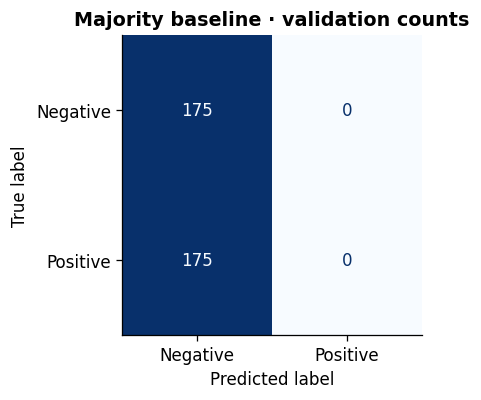

In [ ]:
from sklearn.dummy import DummyClassifier
# G07 — Create the no-text reference that always predicts the most common training class.
baseline = evaluate(DummyClassifier(strategy='most_frequent'), 'Majority baseline')
fig, ax = plt.subplots(figsize=(4.8, 3.6))
ConfusionMatrixDisplay.from_predictions(y_val, baseline.predict(X_val_tfidf),
    labels=[0, 1], display_labels=CLASS_NAMES, cmap='Blues', colorbar=False, ax=ax)
ax.set_title('Majority baseline · validation counts')
plt.tight_layout(); plt.show()

**Tuning**

We try to find best combination for C and SVD size. For every combination SVD is applied on training set, logistic regression model is trained on this set and then we calculate measures on development set

SVD k  = 100,300,500,1000,2000

1.  small k -> big compression
2.  large k -> more info. If 5000 TF-IDF means no compression



C = 0.01, 0.1, 1, 10, 100, 1000

1.  small C (0.01) -> strong regularization
2.  large C (1000) -> weak regularization



In [ ]:
from sklearn.linear_model import LogisticRegression
for k in [100, 300, 500, 1000, 2000]:
    _, X_tr_k, X_va_k = apply_svd(k, X_train_tfidf, X_val_tfidf)   # SVD learned on training data
    for C in [0.01, 0.1, 1, 10, 100, 1000]:
        evaluate(LogisticRegression(C=C, l1_ratio=0.0, solver='lbfgs', max_iter=1000),
                 f'LR + SVD {k}, C={C}', X_tr=X_tr_k, X_va=X_va_k)

# all results, best dev score first
display(pd.DataFrame(results).T.sort_values('Validation macro F1', ascending=False).round(3))

LR + SVD 100, C=0.01: train macro F1 0.860; validation macro F1 0.777
LR + SVD 100, C=0.1: train macro F1 0.869; validation macro F1 0.783
LR + SVD 100, C=1: train macro F1 0.881; validation macro F1 0.803
LR + SVD 100, C=10: train macro F1 0.894; validation macro F1 0.834
LR + SVD 100, C=100: train macro F1 0.902; validation macro F1 0.848
LR + SVD 100, C=1000: train macro F1 0.907; validation macro F1 0.849
LR + SVD 300, C=0.01: train macro F1 0.886; validation macro F1 0.803
LR + SVD 300, C=0.1: train macro F1 0.896; validation macro F1 0.808
LR + SVD 300, C=1: train macro F1 0.929; validation macro F1 0.820
LR + SVD 300, C=10: train macro F1 0.957; validation macro F1 0.851
LR + SVD 300, C=100: train macro F1 0.979; validation macro F1 0.863
LR + SVD 300, C=1000: train macro F1 0.999; validation macro F1 0.840
LR + SVD 500, C=0.01: train macro F1 0.904; validation macro F1 0.811
LR + SVD 500, C=0.1: train macro F1 0.911; validation macro F1 0.814
LR + SVD 500, C=1: train macro F1 0

,Train macro F1,Validation macro F1,Validation positive F1,Validation accuracy,Classifier training ms,Classifier predict ms
"LR + SVD 500, C=100",0.998,0.874,0.871,0.874,44.613,0.792
"LR + SVD 500, C=1000",1.000,0.869,0.865,0.869,49.363,0.775
"LR + SVD 500, C=10",0.985,0.868,0.865,0.869,45.230,0.780
"LR + SVD 1000, C=100",1.000,0.866,0.862,0.866,66.557,0.968
"LR + SVD 1000, C=1000",1.000,0.866,0.862,0.866,60.087,2.569
"LR + SVD 300, C=100",0.979,0.863,0.861,0.863,10.529,0.545
"LR + SVD 2000, C=1000",1.000,0.863,0.860,0.863,104.081,1.061
"LR + SVD 1000, C=10",1.000,0.863,0.860,0.863,55.175,2.962
"LR + SVD 2000, C=10",1.000,0.863,0.860,0.863,117.324,1.050
"LR + SVD 2000, C=100",1.000,0.860,0.857,0.860,103.551,1.076


**No SVD results - using plain TF_IDF as calculated above**

In [ ]:
for C in [1, 10, 100, 1000]:
    evaluate(LogisticRegression(C=C, l1_ratio=0.0, solver='lbfgs', max_iter=1000), f'LR no SVD, C={C}')

LR no SVD, C=1: train macro F1 0.976; validation macro F1 0.849
LR no SVD, C=10: train macro F1 1.000; validation macro F1 0.863
LR no SVD, C=100: train macro F1 1.000; validation macro F1 0.860
LR no SVD, C=1000: train macro F1 1.000; validation macro F1 0.857


**Comparing with and without SVD on dev data to see if SVD actually helps**

With SVD: C = 100, k =500 Macro-F1 = 0.874


Without SVD: C = 10 Macro-F1 = 0.863

**Train model based on best k,C**

According to above best is k=500 and C=100

In [ ]:
BEST_K = 500
BEST_C = 100

svd_final, X_train_final, X_val_final = apply_svd(BEST_K, X_train_tfidf, X_val_tfidf)
final_model = evaluate(LogisticRegression(C=BEST_C, l1_ratio=0.0, solver='lbfgs', max_iter=1000),
                       'Final model (SVD 500, C=100)', X_tr=X_train_final, X_va=X_val_final)

Final model (SVD 500, C=100): train macro F1 0.998; validation macro F1 0.874


**Final evaluation on the test set**

We report accuracy, macro-F1, positive-class F1, ROC AUC and average precision

In [ ]:
from sklearn.metrics import roc_auc_score, average_precision_score

X_test = sealed_test.text.to_numpy()
y_test = sealed_test.label.to_numpy()

# same data transfornations as the training data used to train model
X_test_tfidf = vectorizer.transform(X_test)          # same vocabulary and IDF
X_test_final = svd_final.transform(X_test_tfidf)     # use SVD on tf-idf vectors

# G20 — Get Positive-class probabilities from the frozen final model on the test set.
# 1 column for each class. 1st is negative, 2nd is positive (zero based index so 1 is positive)
test_probability = final_model.predict_proba(X_test_final)[:, 1]
print(test_probability)
test_prediction = (test_probability > .5).astype(int)
final_metrics = {
    'Accuracy': accuracy_score(y_test, test_prediction),
    'Macro F1': f1_score(y_test, test_prediction, average='macro'),
    'Positive F1': f1_score(y_test, test_prediction),
    'ROC AUC': roc_auc_score(y_test, test_probability),
    'Average precision': average_precision_score(y_test, test_probability),
}
display(pd.Series(final_metrics, name='Final held-out report').round(3).to_frame())
print(final_model.classes_)
print(classification_report(y_test, test_prediction, labels=[0, 1],
                            target_names=CLASS_NAMES, digits=3, zero_division=0))

[9.45878197e-01 4.19095014e-01 6.43083003e-01 1.38491149e-02
 2.01328362e-02 3.25124645e-01 9.89418751e-01 3.15685826e-03
 4.13946379e-02 3.51029614e-01 8.08043964e-02 2.21196945e-01
 6.37928039e-01 9.97932597e-01 1.91756884e-01 1.67906243e-01
 5.82683558e-01 9.81839566e-01 9.75979357e-04 9.97644096e-01
 9.10811073e-02 9.96172436e-01 1.53585448e-01 9.82037112e-01
 2.28751680e-02 3.18023335e-02 2.87529462e-01 9.94085877e-01
 9.48853562e-01 9.56465874e-01 1.11377993e-01 5.08522997e-01
 9.33200355e-02 9.97060562e-01 4.35779959e-01 7.19235429e-01
 9.83693378e-01 9.15264051e-01 1.92244975e-01 9.86604744e-01
 4.85801906e-03 3.08727242e-01 9.82261515e-01 3.48693871e-03
 1.46306999e-02 9.95063968e-01 9.76849612e-01 5.64331358e-03
 2.41439398e-03 5.49941853e-01 8.32935842e-01 9.85326457e-01
 1.99650114e-01 5.23327152e-02 1.88709177e-02 8.18694215e-02
 9.25547539e-01 5.77879716e-01 4.35535749e-01 3.73364712e-02
 2.40676841e-01 2.10484643e-01 9.63224118e-01 2.16466568e-02
 9.48812372e-01 1.460004

,Final held-out report
Accuracy,0.850
Macro F1,0.850
Positive F1,0.847
ROC AUC,0.934
Average precision,0.925


[0 1]
              precision    recall  f1-score   support

    Negative      0.839     0.867     0.852       300
    Positive      0.862     0.833     0.847       300

    accuracy                          0.850       600
   macro avg      0.850     0.850     0.850       600
weighted avg      0.850     0.850     0.850       600



**i and ii. Result tables (training, development, test).**

Precision, recall, F1, precision-recall AUC scores, for each class and classifier,
separately for the training, development, and test subsets

Macro-averaged precision, recall, F1, precision-recall AUC scores (all computed by
averaging the corresponding scores of the previous bullet over the classes), for each
classifier, separately for the training, development, and test subsets.

In [ ]:
from sklearn.metrics import precision_score, recall_score

def metrics_row(model, X, y):

  prediction = model.predict(X);
  probability = model.predict_proba(X); # 2 columns 1 for every class

  P = precision_score(y, prediction, average=None, zero_division=0)   # [Negative, Positive]
  R = recall_score(y, prediction, average=None, zero_division=0)
  F = f1_score(y, prediction, average=None, zero_division=0)

  # AUC for positive and negative
  AP_neg = average_precision_score(y == 0, probability[:, 0])
  AP_pos = average_precision_score(y == 1, probability[:, 1])

  row = {
    'Negative P': P[0], 'Negative R': R[0], 'Negative F1': F[0], 'Negative PR-AUC': AP_neg,
    'Positive P': P[1], 'Positive R': R[1], 'Positive F1': F[1], 'Positive PR-AUC': AP_pos,
  }

  row['Macro P'] = (P[0] + P[1]) / 2  #precision_score(y, prediction, average='macro', zero_division=0)
  row['Macro R'] = (R[0] + R[1]) / 2  #recall_score(y, prediction, average='macro', zero_division=0)
  row['Macro F1'] = (F[0] + F[1]) / 2 #f1_score(y, prediction, average='macro', zero_division=0)
  row['Macro PR-AUC'] = (AP_neg + AP_pos) / 2 # MAP

  return row;

def create_table(X_baseline, X_lr, y):
  rows = {}
  rows['Majority baseline'] = metrics_row(baseline, X_baseline, y)
  rows['Logistic regression (SVD 500, C=100)'] = metrics_row(final_model, X_lr, y)
  return pd.DataFrame(rows).T

# the 3 tables
print('Training set')
display(create_table(X_train_tfidf, X_train_final, y_train))

print('Development/Validation set')
display(create_table(X_val_tfidf, X_val_final, y_val))

print('Test set')
display(create_table(X_test_tfidf, X_test_final, y_test))



Training set


,Negative P,Negative R,Negative F1,Negative PR-AUC,Positive P,Positive R,Positive F1,Positive PR-AUC,Macro P,Macro R,Macro F1,Macro PR-AUC
Majority baseline,0.5,1.00000,0.666667,0.5,0.000000,0.0,0.000000,0.5,0.250000,0.500000,0.333333,0.5
"Logistic regression (SVD 500, C=100)",1.0,0.99619,0.998092,1.0,0.996205,1.0,0.998099,1.0,0.998102,0.998095,0.998095,1.0


Development/Validation set


,Negative P,Negative R,Negative F1,Negative PR-AUC,Positive P,Positive R,Positive F1,Positive PR-AUC,Macro P,Macro R,Macro F1,Macro PR-AUC
Majority baseline,0.500000,1.000000,0.666667,0.50000,0.00000,0.000000,0.000000,0.500000,0.250000,0.500000,0.333333,0.500000
"Logistic regression (SVD 500, C=100)",0.854054,0.902857,0.877778,0.94546,0.89697,0.845714,0.870588,0.947714,0.875512,0.874286,0.874183,0.946587


Test set


,Negative P,Negative R,Negative F1,Negative PR-AUC,Positive P,Positive R,Positive F1,Positive PR-AUC,Macro P,Macro R,Macro F1,Macro PR-AUC
Majority baseline,0.50000,1.000000,0.666667,0.500000,0.000000,0.000000,0.000000,0.500000,0.250000,0.50,0.333333,0.500000
"Logistic regression (SVD 500, C=100)",0.83871,0.866667,0.852459,0.934952,0.862069,0.833333,0.847458,0.925394,0.850389,0.85,0.849958,0.930173


**iii. Learning curves**

For each classifier, two learning curves showing macro-averaged F1 computed on (i)
the increasingly larger (e.g., 10%, 20%, etc.) subset of the training set the classifier
has encountered, (ii) the (always entire) development subset.

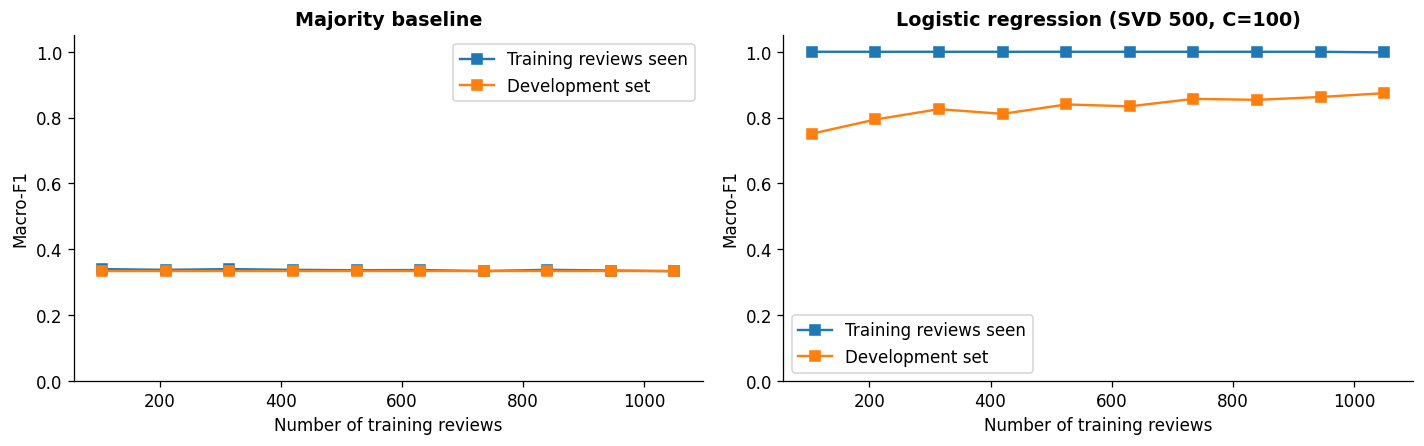

In [ ]:
percentages = [0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1]

lr_macro_f1_train = []
lr_macro_f1_dev = []

majority_macro_f1_train = []
majority_macro_f1_dev = []

data_sizes = [int(percentage * len(X_train)) for percentage in percentages]

for percentage in percentages:
  n = int(percentage * len(X_train))

  # Logistic regression
  lr_model = LogisticRegression(C=BEST_C, l1_ratio=0.0, solver='lbfgs', max_iter=1000)
  lr_model.fit(X_train_final[:n], y_train[:n])     # training data with SVD
  lr_macro_f1_train.append(f1_score(y_train[:n], lr_model.predict(X_train_final[:n]), average='macro', zero_division=0))
  lr_macro_f1_dev.append(f1_score(y_val, lr_model.predict(X_val_final), average='macro', zero_division=0))

  # Majority
  majority_model = DummyClassifier(strategy='most_frequent')
  majority_model.fit(X_train_tfidf[:n], y_train[:n]) # ignores features, always tells the same so SVD has no point
  majority_macro_f1_train.append(f1_score(y_train[:n], majority_model.predict(X_train_tfidf[:n]), average='macro', zero_division=0))
  majority_macro_f1_dev.append(f1_score(y_val, majority_model.predict(X_val_tfidf), average='macro', zero_division=0))

# side by side diagrams
fig, axes = plt.subplots(1, 2, figsize=(12.5, 4))

axes[0].plot(data_sizes, majority_macro_f1_train, marker='s', label='Training reviews seen')
axes[0].plot(data_sizes, majority_macro_f1_dev, marker='s', label='Development set')
axes[0].set(title='Majority baseline', xlabel='Number of training reviews', ylabel='Macro-F1', ylim=(0, 1.05))
axes[0].legend()

axes[1].plot(data_sizes, lr_macro_f1_train, marker='s', label='Training reviews seen')
axes[1].plot(data_sizes, lr_macro_f1_dev, marker='s', label='Development set')
axes[1].set(title='Logistic regression (SVD 500, C=100)', xlabel='Number of training reviews', ylabel='Macro-F1', ylim=(0, 1.05))
axes[1].legend()

plt.tight_layout(); plt.show()


**Statistics of data in all sets**

In [ ]:
stats = {}
for name, texts, labels in [('Training', X_train, y_train),
                            ('Development', X_val, y_val),
                            ('Test', X_test, y_test)]:
    lengths = [len(text.split()) for text in texts]     # number of tokens in each review
    stats[name] = {
        'Reviews': len(texts),
        'Negative / Positive': f'{sum(labels == 0)} / {sum(labels == 1)}',
        'Average length (tokens)': round(np.mean(lengths), 1),
        'Median length (tokens)': int(np.median(lengths)),
    }
display(pd.DataFrame(stats))

,Training,Development,Test
Reviews,1050,350,600
Negative / Positive,525 / 525,175 / 175,300 / 300
Average length (tokens),741.2,758.3,748.4
Median length (tokens),698,686,698


**Centroids for text embeddings**

GloVe gives for each english word its vector, in this case 100 per word. Text is taken from Wikipedia and news articles. Words appeaaring in similar context end up with similar vectors

In [51]:
import gensim.downloader as api

MODEL_NAME = 'glove-wiki-gigaword-100'

def load_vectors(name=MODEL_NAME):
    '''Return gensim KeyedVectors for the requested pre-trained model.'''
    return api.load(name)

kv_glove = load_vectors()
print(f'Loaded {MODEL_NAME}: {len(kv_glove):,} words, {kv_glove.vector_size} dimensions')


Loaded glove-wiki-gigaword-100: 400,000 words, 100 dimensions


**The centroid function**

two different approaches as described in slide 50 of lecture

In [57]:
def text_centroid_tf(review, model):
    '''Mean vector of all in-vocabulary word vectors in the text, INCLUDING stopwords.
    Returns a zero vector if no token is in the vocabulary (e.g. empty documents).'''
    vectors = []
    for word in review:
        if word in model.key_to_index:
            vectors.append(model[word])
    if not vectors:
        return np.zeros(model.vector_size, dtype=np.float32)
    return np.mean(vectors, axis=0)

idfs_vectorizer = TfidfVectorizer(preprocessor=normalize_text, ngram_range=(1, 1)).fit(X_train)
words = idfs_vectorizer.get_feature_names_out()
values = idfs_vectorizer.idf_

idf = {}
for i in range(len(words)):
    idf[words[i]] = values[i]

def text_centroid_idf(tokens, model):
    total = np.zeros(model.vector_size)
    weight_sum = 0.0
    for word in tokens:
        if word in model.key_to_index and word in idf:
            total += model[word] * idf[word] # tf * idf
            weight_sum += idf[word]          # loops through all words not distinct
    if weight_sum == 0:
        return total
    return total / weight_sum

**Training and results with tf centroids**

In [58]:
def make_centroids(texts, centroid_function):
    vectors = []
    for doc in texts:
        tokens = normalize_text(doc).split()
        vectors.append(centroid_function(tokens, kv_glove))
    return np.stack(vectors)

# tf
X_train_cent = make_centroids(X_train, text_centroid_tf)
X_val_cent = make_centroids(X_val, text_centroid_tf)
X_test_cent = make_centroids(X_test, text_centroid_tf)
print('Plain centroids:', X_train_cent.shape, X_val_cent.shape, X_test_cent.shape)

# idf
X_train_cidf = make_centroids(X_train, text_centroid_idf)
X_val_cidf = make_centroids(X_val, text_centroid_idf)
X_test_cidf = make_centroids(X_test, text_centroid_idf)
print('IDF-weighted centroids:', X_train_cidf.shape, X_val_cidf.shape, X_test_cidf.shape)

Plain centroids: (1050, 100) (350, 100) (600, 100)
IDF-weighted centroids: (1050, 100) (350, 100) (600, 100)


In [70]:
for C in [0.01, 0.1, 1, 10, 100, 1000, 2000]:
    evaluate(LogisticRegression(C=C, l1_ratio=0.0, solver='lbfgs', max_iter=1000),
             f'LR tf centroids, C={C}', X_tr=X_train_cent, X_va=X_val_cent)

for C in [0.01, 0.1, 1, 10, 100, 1000, 2000, 3000]:
    evaluate(LogisticRegression(C=C, l1_ratio=0.0, solver='lbfgs', max_iter=1000),
             f'LR idf centroids, C={C}', X_tr=X_train_cidf, X_va=X_val_cidf)

LR tf centroids, C=0.01: train macro F1 0.668; validation macro F1 0.651
LR tf centroids, C=0.1: train macro F1 0.701; validation macro F1 0.683
LR tf centroids, C=1: train macro F1 0.745; validation macro F1 0.728
LR tf centroids, C=10: train macro F1 0.823; validation macro F1 0.771
LR tf centroids, C=100: train macro F1 0.842; validation macro F1 0.760
LR tf centroids, C=1000: train macro F1 0.846; validation macro F1 0.760
LR tf centroids, C=2000: train macro F1 0.841; validation macro F1 0.760
LR idf centroids, C=0.01: train macro F1 0.721; validation macro F1 0.668
LR idf centroids, C=0.1: train macro F1 0.724; validation macro F1 0.684
LR idf centroids, C=1: train macro F1 0.766; validation macro F1 0.707
LR idf centroids, C=10: train macro F1 0.810; validation macro F1 0.731
LR idf centroids, C=100: train macro F1 0.826; validation macro F1 0.737
LR idf centroids, C=1000: train macro F1 0.824; validation macro F1 0.728
LR idf centroids, C=2000: train macro F1 0.824; validation 

In [71]:
BEST_C_CENT_TF = 10
tf_cent_model = evaluate(LogisticRegression(C=BEST_C_CENT_TF, l1_ratio=0.0, solver='lbfgs', max_iter=1000),
                      f'LR centroids (final, C={BEST_C_CENT_TF})', X_tr=X_train_cent, X_va=X_val_cent)

BEST_C_CENT_IDF = 100
idf_cent_model = evaluate(LogisticRegression(C=BEST_C_CENT_IDF, l1_ratio=0.0, solver='lbfgs', max_iter=1000),
                      f'LR centroids (final, C={BEST_C_CENT_IDF})', X_tr=X_train_cidf, X_va=X_val_cidf)

LR centroids (final, C=10): train macro F1 0.823; validation macro F1 0.771
LR centroids (final, C=100): train macro F1 0.826; validation macro F1 0.737


In [72]:
from IPython.display import display

def create_table(X_baseline, X_lr, X_cent, X_cidf, y):
  rows = {}
  rows['Majority baseline'] = metrics_row(baseline, X_baseline, y)
  rows['Logistic regression (SVD 500, C=100)'] = metrics_row(final_model, X_lr, y)
  rows['Logistic regression (GloVe TF centroids)'] = metrics_row(fitted_models[f'LR centroids (final, C={BEST_C_CENT_TF})'], X_cent, y)
  rows['Logistic regression (GloVe IDF centroids)'] = metrics_row(fitted_models[f'LR centroids (final, C={BEST_C_CENT_IDF})'], X_cidf, y)
  return pd.DataFrame(rows).T.round(3)


print('Training set')
display(create_table(X_train_tfidf, X_train_final, X_train_cent, X_train_cidf, y_train))

print('Development set')
display(create_table(X_val_tfidf, X_val_final, X_val_cent, X_val_cidf, y_val))

print('Test set')
display(create_table(X_test_tfidf, X_test_final, X_test_cent, X_test_cidf, y_test))

Training set


,Negative P,Negative R,Negative F1,Negative PR-AUC,Positive P,Positive R,Positive F1,Positive PR-AUC,Macro P,Macro R,Macro F1,Macro PR-AUC
Majority baseline,0.500,1.000,0.667,0.500,0.000,0.000,0.000,0.500,0.250,0.500,0.333,0.500
"Logistic regression (SVD 500, C=100)",1.000,0.996,0.998,1.000,0.996,1.000,0.998,1.000,0.998,0.998,0.998,1.000
Logistic regression (GloVe TF centroids),0.809,0.846,0.827,0.891,0.838,0.800,0.819,0.895,0.824,0.823,0.823,0.893
Logistic regression (GloVe IDF centroids),0.825,0.827,0.826,0.896,0.826,0.825,0.826,0.885,0.826,0.826,0.826,0.891


Development set


,Negative P,Negative R,Negative F1,Negative PR-AUC,Positive P,Positive R,Positive F1,Positive PR-AUC,Macro P,Macro R,Macro F1,Macro PR-AUC
Majority baseline,0.500,1.000,0.667,0.500,0.000,0.000,0.000,0.500,0.250,0.500,0.333,0.500
"Logistic regression (SVD 500, C=100)",0.854,0.903,0.878,0.945,0.897,0.846,0.871,0.948,0.876,0.874,0.874,0.947
Logistic regression (GloVe TF centroids),0.771,0.771,0.771,0.801,0.771,0.771,0.771,0.865,0.771,0.771,0.771,0.833
Logistic regression (GloVe IDF centroids),0.746,0.720,0.733,0.790,0.729,0.754,0.742,0.838,0.737,0.737,0.737,0.814


Test set


,Negative P,Negative R,Negative F1,Negative PR-AUC,Positive P,Positive R,Positive F1,Positive PR-AUC,Macro P,Macro R,Macro F1,Macro PR-AUC
Majority baseline,0.500,1.000,0.667,0.500,0.000,0.000,0.000,0.500,0.250,0.500,0.333,0.500
"Logistic regression (SVD 500, C=100)",0.839,0.867,0.852,0.935,0.862,0.833,0.847,0.925,0.850,0.850,0.850,0.930
Logistic regression (GloVe TF centroids),0.748,0.780,0.763,0.799,0.770,0.737,0.753,0.811,0.759,0.758,0.758,0.805
Logistic regression (GloVe IDF centroids),0.763,0.707,0.734,0.786,0.727,0.780,0.752,0.791,0.745,0.743,0.743,0.789
